In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/telco_churn.csv")
print(df.shape)
print(df["Churn"].value_counts())
print("Churn rate: %.2f%%" % (df["Churn"].eq("Yes").mean() * 100))

(7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn rate: 26.54%


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum(),
      "| tenure of those rows:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

df["TotalCharges"] = df["TotalCharges"].fillna(0)   # brand-new customers, not billed yet
df["churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["Churn"])

Blank TotalCharges: 11 | tenure of those rows: [0]


                 mean  count
Contract                    
Month-to-month  0.427   3875
One year        0.113   1473
Two year        0.028   1695 

                      mean  count
TechSupport                      
No                   0.416   3473
No internet service  0.074   1526
Yes                  0.152   2044 

                  mean  count
InternetService              
DSL              0.190   2421
Fiber optic      0.419   3096
No               0.074   1526 

                            mean  count
PaymentMethod                          
Bank transfer (automatic)  0.167   1544
Credit card (automatic)    0.152   1522
Electronic check           0.453   2365
Mailed check               0.191   1612 



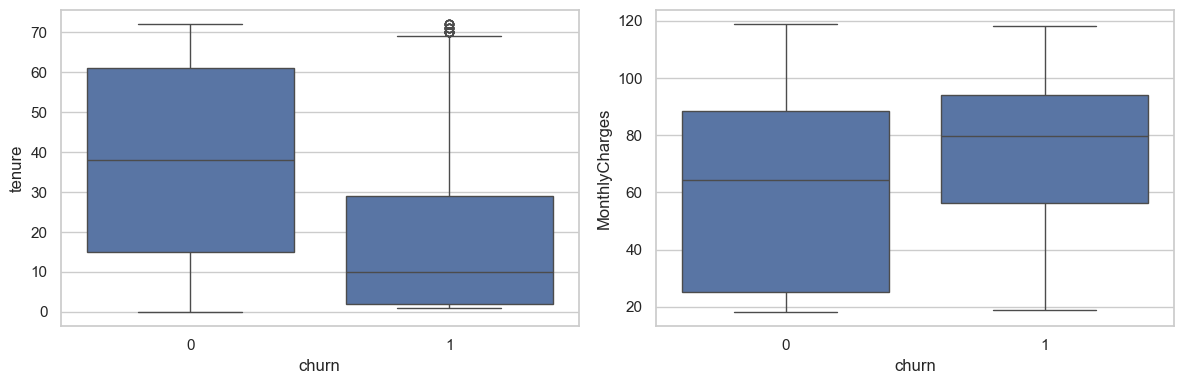

In [3]:
for col in ["Contract", "TechSupport", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["churn"].agg(["mean", "count"]).round(3), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="churn", y="tenure", data=df, ax=ax[0])
sns.boxplot(x="churn", y="MonthlyCharges", data=df, ax=ax[1])
plt.tight_layout()
plt.savefig("../reports/figures/tenure_charges_by_churn.png", dpi=150)
plt.show()